#### **02 — Análise Exploratória de Risco (Behavior Score)**

**Objetivo:** EDA orientada a comportamento financeiro, discretização de variáveis, mensuração univariada de risco (WoE/IV), estabilidade de safras e diagnóstico de multicolinearidade para a mesa de crédito.

**Base:** `data/01_prata/treino_fe.parquet` (somente treino, com atributos já criados no notebook 01).

**Padrão visual:** clean corporativo, paleta monocromática de verdes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# ==============================================================================
# CONFIGURAÇÃO DE PALETA CORPORATIVA: TONALIDADES DE VERDE
# ==============================================================================
GREEN_DARK   = "#1B4D3E"  # Verde Floresta Profundo (Ênfase/Linhas críticas)
GREEN_MID    = "#2E8B57"  # SeaGreen / Esmeralda (Barras principais)
GREEN_LIGHT  = "#66BB6A"  # Verde Claro Médio
GREEN_PALE   = "#A3E4D7"  # Menta Pálido (Fundos/Volumes secundários)
GREEN_ACCENT = "#0E6251"  # Verde Petróleo (Destaques executivos)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.size": 11,
    "axes.edgecolor": "#D5D8DC",
    "axes.linewidth": 0.8,
})

TARGET = "default"

##### **1. Funções Core do Pipeline**

Cálculo de WoE/IV com discretização em quantis, tratamento de nulos em bin dedicado e *Laplace smoothing*; funções de visualização executiva.

In [2]:
from modelo_credito.eda import woe_iv_table as calcular_woe_iv


In [3]:
from modelo_credito.plots import plot_estabilidade_safra


In [4]:
from modelo_credito.plots import plot_ranking_iv


In [5]:
from modelo_credito.plots import plot_curva_monotonicidade


In [6]:
from modelo_credito.plots import plot_matriz_spearman


#### **2. Carga e Visão Geral da Base**

In [7]:
df = pd.read_parquet('../data/01_prata/treino_fe.parquet')

df["SAFRA_LABEL"] = df["SAFRA"].astype(str).str[:4] + "-" + df["SAFRA"].astype(str).str[4:]
df = df.sort_values(["SAFRA", "ID"]).reset_index(drop=True)

print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Taxa de default global: {df[TARGET].mean():.2%}")
print(f"Valores ausentes totais: {df.isna().sum().sum()}")
df.head()

Dimensões: 18,000 linhas x 39 colunas
Taxa de default global: 23.06%
Valores ausentes totais: 1192


,ID,SAFRA,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,...,SUM_PAY,AVG_PAY,MAX_PAY,UTILIZACAO,UTIL_MEDIA,PCT_PAGAMENTO,FREQ_ATRASO,MAX_ATRASO,LIMIT_PER_CAPITA,SAFRA_LABEL
0,1,200510,20000,2,2,1,24,2.0,2.0,-1.0,...,689.0,114.833333,689.0,0.195650,0.064200,0.000000,2,2.0,833.333333,2005-10
1,2,200510,120000,2,2,2,26,-1.0,2.0,0.0,...,5000.0,833.333333,2000.0,0.022350,0.023718,0.000000,2,2.0,4615.384615,2005-10
2,3,200510,90000,2,2,2,34,0.0,0.0,0.0,...,11018.0,1836.333333,5000.0,0.324878,0.188246,0.051917,0,0.0,2647.058824,2005-10
3,4,200510,50000,2,2,1,37,0.0,0.0,0.0,...,8388.0,1398.000000,2019.0,0.939800,0.771113,0.042562,0,0.0,1351.351351,2005-10
4,5,200510,50000,1,2,1,57,-1.0,0.0,-1.0,...,31570.5,5261.750000,10048.2,0.172340,0.364463,0.232099,0,0.0,877.192982,2005-10


In [8]:
df[[TARGET, "LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1", "PAY_AMT1"]].describe().T

,count,mean,std,min,25%,50%,75%,max
default,18000.0,0.230556,0.421200,0.0,0.0,0.0,0.0,1.0
LIMIT_BAL,18000.0,162902.426667,129503.322618,10000.0,50000.0,130000.0,230000.0,1000000.0
AGE,18000.0,35.475556,9.294161,21.0,28.0,34.0,41.0,75.0
PAY_0,18000.0,0.001056,1.036234,-2.0,-1.0,0.0,0.0,2.0
BILL_AMT1,18000.0,50051.125278,71620.269059,-1.0,3675.0,22449.5,65000.5,964511.0
PAY_AMT1,18000.0,3352.631722,3281.757136,0.0,949.0,2087.0,5000.0,10087.8


#### **3. Estabilidade Temporal de Safras (Bad Rate vs. Volume)**

Leitura: se o aumento do default coincide com expansão de volume, há indício de **seleção adversa** (relaxamento de política). Com volume estável, a causa tende a ser **exógena** (estresse macro).

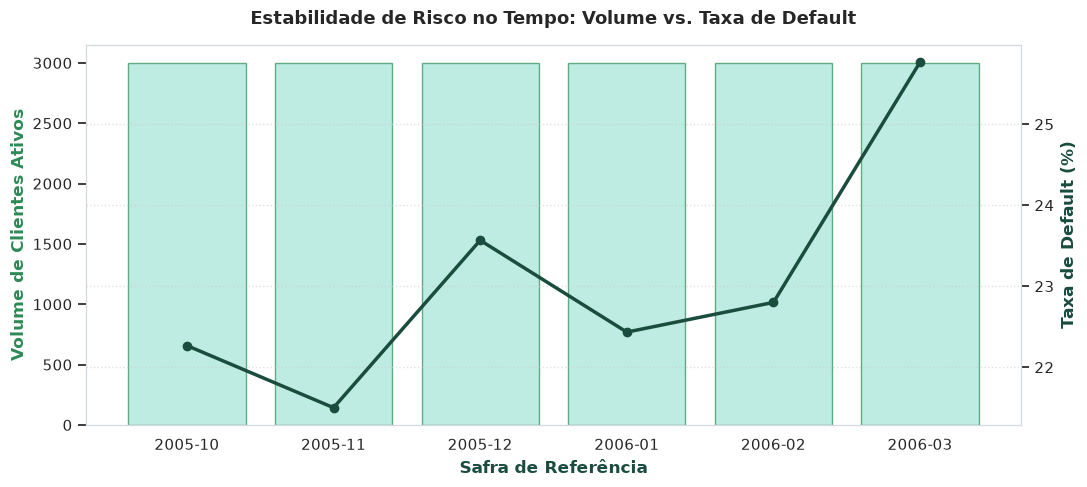

,volume,bads,bad_rate
SAFRA_LABEL,,,
2005-10,3000,668,22.27
2005-11,3000,645,21.50
2005-12,3000,707,23.57
2006-01,3000,673,22.43
2006-02,3000,684,22.80
2006-03,3000,773,25.77


In [9]:
plot_estabilidade_safra(df, "SAFRA_LABEL", TARGET)

df.groupby("SAFRA_LABEL").agg(
    volume=(TARGET, "count"),
    bads=(TARGET, "sum"),
    bad_rate=(TARGET, "mean")
).assign(bad_rate=lambda x: (x["bad_rate"] * 100).round(2))

#### **4. Screening Univariado — Information Value (IV)**

Faixas canônicas: `< 0.02` inexpressivo; `0.02–0.10` fraco; `0.10–0.30` médio; `0.30–0.50` forte; `> 0.50` suspeita de vazamento.

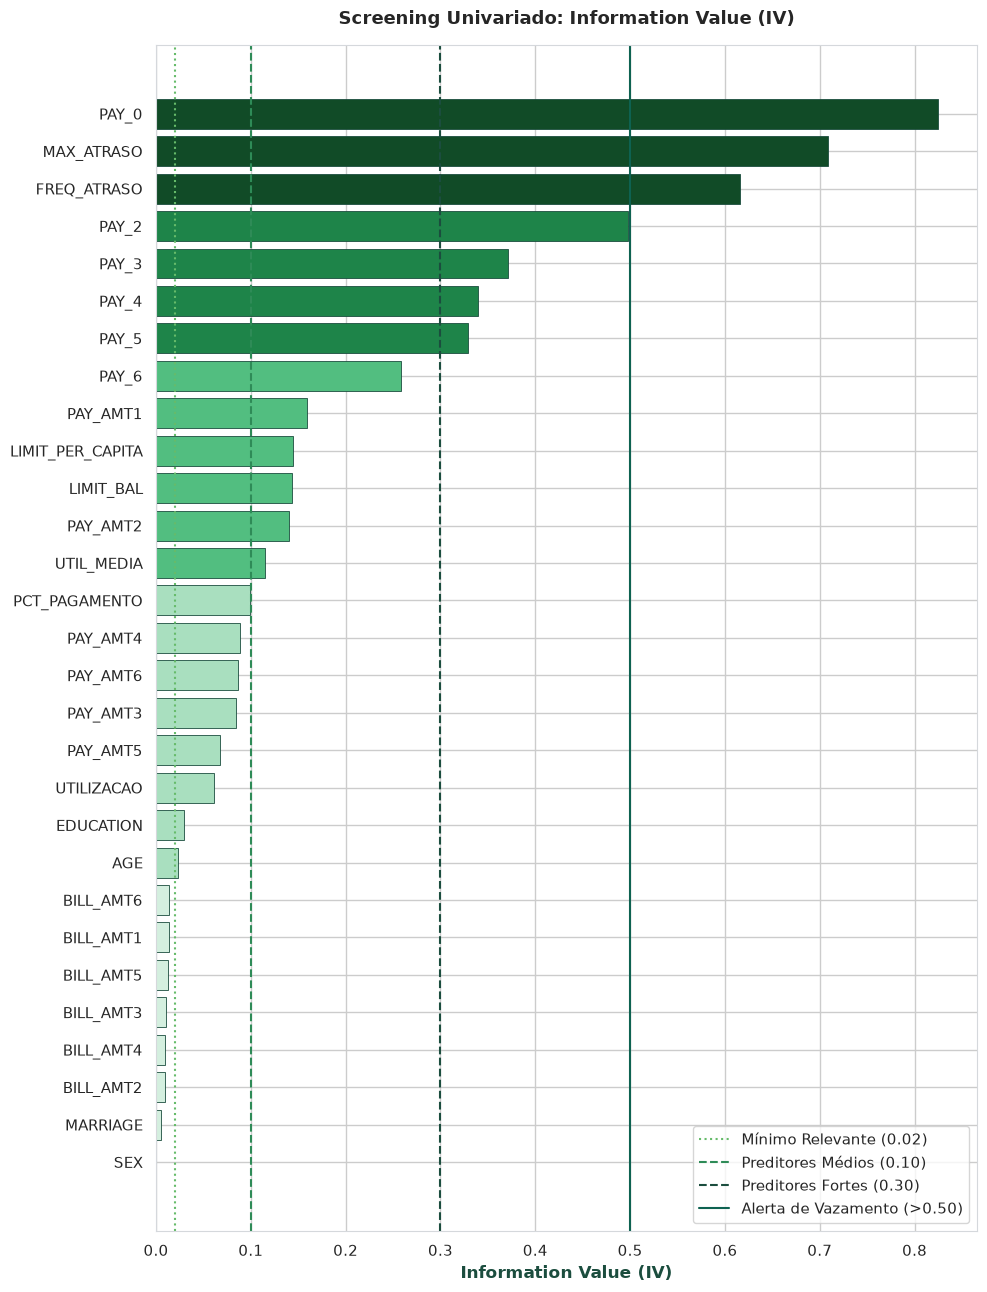

,Feature,IV
0,PAY_0,8.245683e-01
1,MAX_ATRASO,7.089726e-01
2,FREQ_ATRASO,6.153987e-01
3,PAY_2,4.976201e-01
4,PAY_3,3.715797e-01
5,PAY_4,3.394840e-01
6,PAY_5,3.285821e-01
7,PAY_6,2.585768e-01
8,PAY_AMT1,1.597369e-01
9,LIMIT_PER_CAPITA,1.443997e-01


In [10]:
features_continuas = [
    "LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "PAY_AMT1", "PAY_AMT2",
    "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "UTILIZACAO", "PCT_PAGAMENTO", "FREQ_ATRASO", "MAX_ATRASO",
    "UTIL_MEDIA", "LIMIT_PER_CAPITA"
]
features_categoricas = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

iv_df = plot_ranking_iv(df, features_continuas + features_categoricas, TARGET)
iv_df

#### **5. Monotonicidade e WoE por Faixa de Risco**

Curvas monotônicas crescentes de bad rate (e decrescentes de WoE) indicam relação estável e adequada para regressão logística / scorecard. Quebras de monotonicidade sugerem rebinagem.

In [11]:
top_features = ["PAY_0", "MAX_ATRASO", "FREQ_ATRASO", "PAY_2", "PAY_3", "PAY_4"]
top_features


['PAY_0', 'MAX_ATRASO', 'FREQ_ATRASO', 'PAY_2', 'PAY_3', 'PAY_4']

#### **PAY_0 — Status de pagamento mais recente**

Representa o comportamento de pagamento no mês mais recente da base (set/2005): `-2` = sem consumo, `-1` = pagamento integral, `0` = uso de rotativo e `1..8` = meses de atraso.

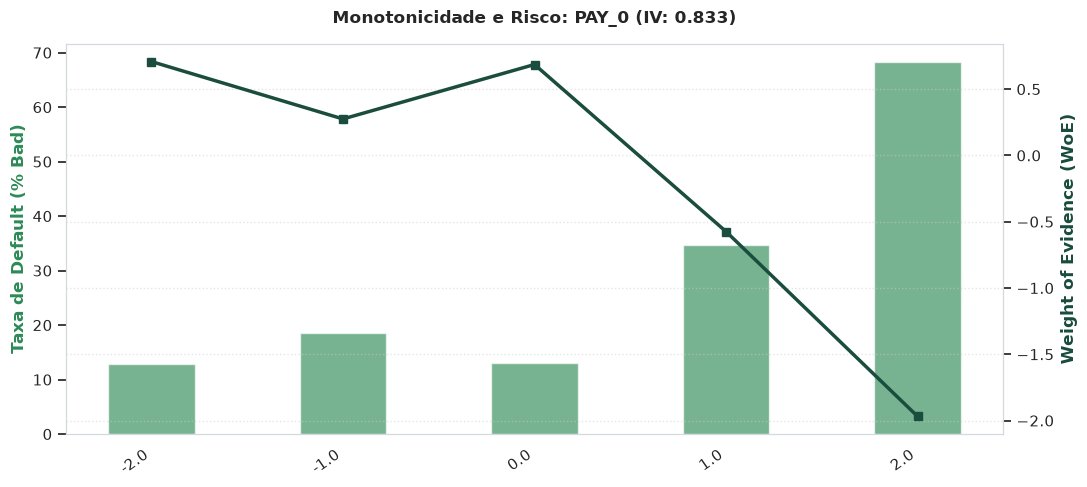

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2.0,1371,176,1195,0.1284,0.7080,0.0310
1,-1.0,3556,659,2897,0.1853,0.2751,0.0138
2,0.0,8741,1146,7595,0.1311,0.6858,0.1867
3,1.0,2347,815,1532,0.3473,-0.5742,0.0493
4,2.0,1985,1354,631,0.6821,-1.9681,0.5525


In [12]:
tabela_pay_0, iv_pay_0 = calcular_woe_iv(df, "PAY_0", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_0, "PAY_0", iv_pay_0)
display(tabela_pay_0[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** é o preditor mais forte do screening (IV ≈ 0,88), com bad rate crescendo de ~12,8% no status `0` para ~33,9% em `1`, ~69,1% em `2` e acima de 75% nos atrasos mais severos. A relação é monotônica a partir do status `0`, o que favorece o uso em scorecard. Deve ser mantida como variável central, preferencialmente tratada como categórica ordinal ou com agrupamento `0 / 1 / 2 / 3+`. O IV acima de 0,50 exige atenção: verificar se o status mais recente não carrega sobreposição temporal com a definição do target (vazamento) e agrupar categorias raras (6 a 8), que têm pouco volume.

##### **MAX_ATRASO — Pior status de atraso observado em seis meses**

Captura a severidade máxima de atraso registrada na janela histórica, independentemente de quando ocorreu.

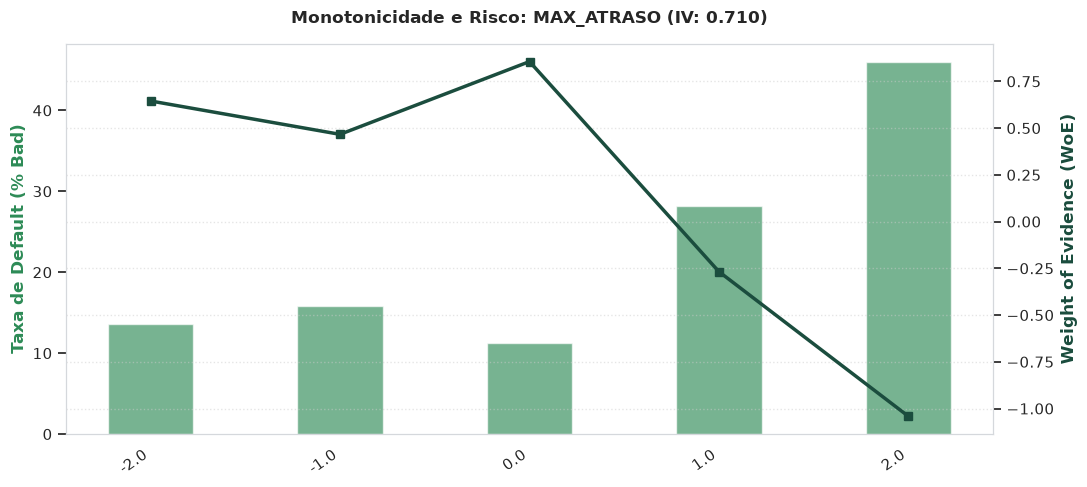

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2.0,967,131,836,0.1355,0.6452,0.0185
1,-1.0,2006,317,1689,0.1580,0.4667,0.0212
2,0.0,8671,979,7692,0.1129,0.8560,0.2734
3,1.0,1102,310,792,0.2813,-0.2680,0.0047
4,2.0,5254,2413,2841,0.4593,-1.0418,0.3920


In [13]:
tabela_max_atraso, iv_max_atraso = calcular_woe_iv(df, "MAX_ATRASO", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_max_atraso, "MAX_ATRASO", iv_max_atraso)
display(tabela_max_atraso[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** apresenta IV ≈ 0,79 e separação clara de risco: bad rate de ~10,8% sem atraso, ~25,0% em atraso leve, ~43,6% em atraso moderado e ~62,9% no pior grupo. É uma variável forte e interpretável para política de crédito. Porém, sua correlação de Spearman com `FREQ_ATRASO` (≈ 0,88) e com `PAY_0` (≈ 0,75) indica redundância. Recomenda-se mantê-la apenas se `FREQ_ATRASO` e `PAY_0` não estiverem no modelo, ou usá-la como representante da severidade histórica após teste de VIF.

#### **FREQ_ATRASO — Frequência de meses com atraso**

Conta quantos dos seis meses analisados apresentaram atraso (`PAY_* > 0`), medindo recorrência e persistência do problema de liquidez.

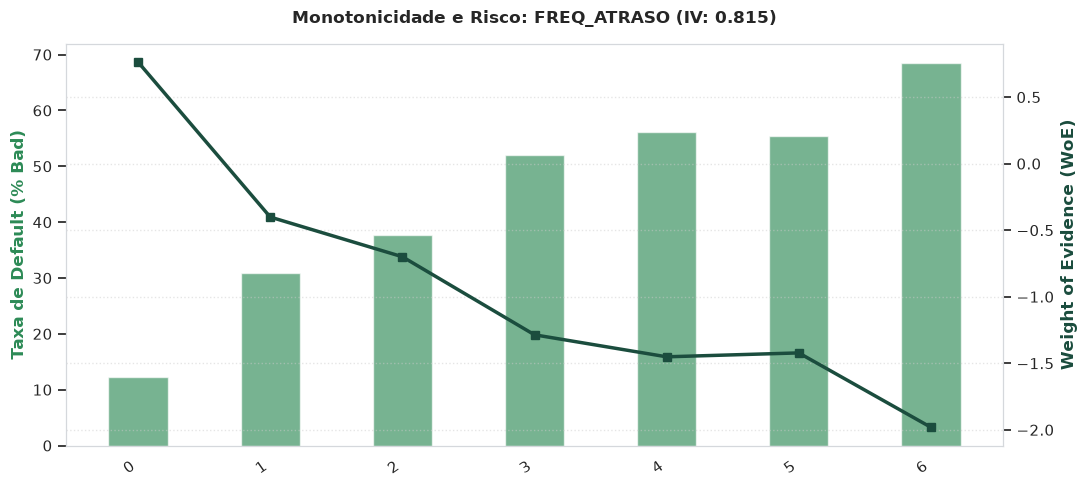

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,0,11644,1427,10217,0.1226,0.7632,0.3005
1,1,2798,865,1933,0.3091,-0.4012,0.0276
2,2,1175,442,733,0.3762,-0.6996,0.0375
3,3,740,385,355,0.5203,-1.2860,0.0864
4,4,570,320,250,0.5614,-1.4514,0.0858
5,5,184,102,82,0.5543,-1.4221,0.0266
6,6,889,609,280,0.6850,-1.9811,0.2508


In [14]:
tabela_freq_atraso, iv_freq_atraso = calcular_woe_iv(df, "FREQ_ATRASO", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_freq_atraso, "FREQ_ATRASO", iv_freq_atraso)
display(tabela_freq_atraso[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** tem IV ≈ 0,86 quando tratada nas categorias originais de contagem, com bad rate crescendo conforme o número de meses em atraso. Isso mostra que recorrência é um sinal comportamental relevante, não apenas a severidade pontual. Apesar disso, é altamente correlacionada com `MAX_ATRASO` (≈ 0,88), então não deve entrar junto dela sem seleção prévia. Se mantida, usar a contagem original (`0, 1, 2, 3+`) em vez de quantis, preservando a leitura de negócio. É candidata a permanecer no modelo no lugar de `MAX_ATRASO` por ser mais estável e interpretável.

#### **PAY_2 — Status de pagamento de dois meses atrás**

Indica o comportamento de pagamento no segundo mês anterior ao corte, ajudando a reconstruir a trajetória recente do cliente.

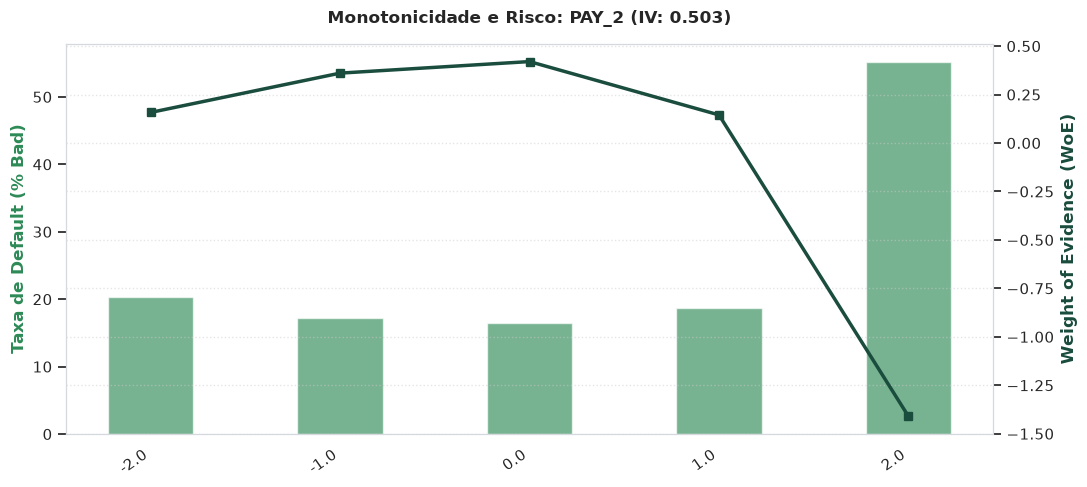

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2.0,2077,423,1654,0.2037,0.1577,0.0027
1,-1.0,3751,648,3103,0.1728,0.3606,0.0245
2,0.0,9371,1541,7830,0.1644,0.4203,0.0815
3,1.0,16,3,13,0.1875,0.1449,0.0000
4,2.0,2785,1535,1250,0.5512,-1.4103,0.3944


In [15]:
tabela_pay_2, iv_pay_2 = calcular_woe_iv(df, "PAY_2", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_2, "PAY_2", iv_pay_2)
display(tabela_pay_2[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** IV ≈ 0,55, com salto de risco a partir do status `2` (atraso de dois meses), chegando a ~55,6%. A variável agrega informação de trajetória que `PAY_0` isoladamente não captura, mas é fortemente correlacionada com `PAY_3` (≈ 0,80) e `PAY_4` (≈ 0,71). Recomenda-se testá-la como complemento a `PAY_0`, mantendo no máximo uma ou duas defasagens no modelo final. Se a correlação gerar instabilidade nos coeficientes, descartar `PAY_2` em favor de `PAY_0`.

#### **PAY_3 — Status de pagamento de três meses atrás**

Representa o comportamento de pagamento no terceiro mês anterior ao corte, capturando atrasos com maior defasagem temporal.

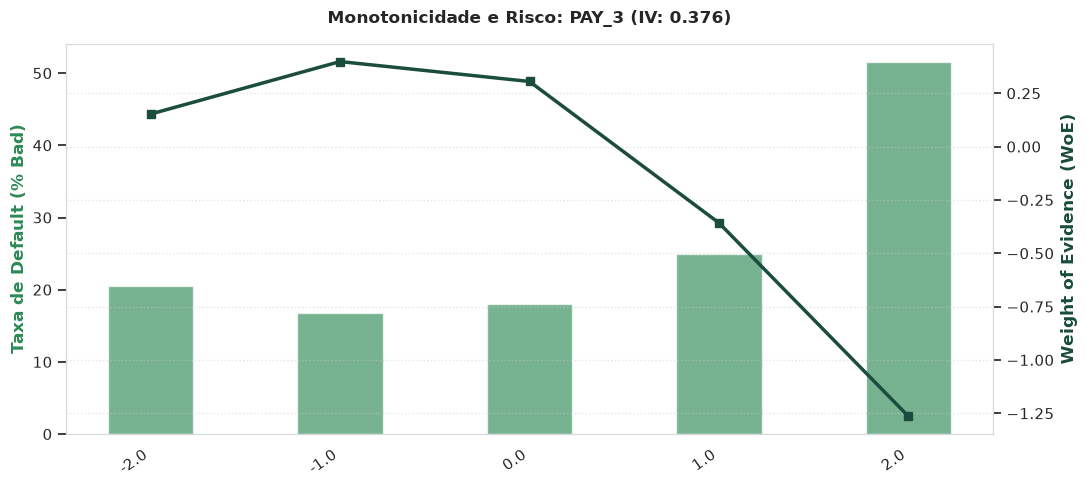

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2.0,2254,461,1793,0.2045,0.1524,0.0028
1,-1.0,3656,612,3044,0.1674,0.3985,0.0288
2,0.0,9421,1704,7717,0.1809,0.3052,0.0447
3,1.0,4,1,3,0.2500,-0.3577,0.0000
4,2.0,2665,1372,1293,0.5148,-1.2643,0.3000


In [16]:
tabela_pay_3, iv_pay_3 = calcular_woe_iv(df, "PAY_3", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_3, "PAY_3", iv_pay_3)
display(tabela_pay_3[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** IV ≈ 0,42, ainda na faixa de preditor forte. O bad rate sobe de ~17,5% no status `0` para ~51,6% em `2` e ~57,5% em `3`. Contudo, a correlação com `PAY_2` (≈ 0,80) e `PAY_4` (≈ 0,80) é alta, e a defasagem maior tende a agregar pouco além das variáveis mais recentes. É útil para análise de tendência, mas deve ser descartada do modelo final se `PAY_0` e `PAY_2` já estiverem presentes.

#### **PAY_4 — Status de pagamento de quatro meses atrás**

Registra o comportamento de pagamento no quarto mês anterior ao corte, sendo a defasagem mais distante analisada neste bloco.

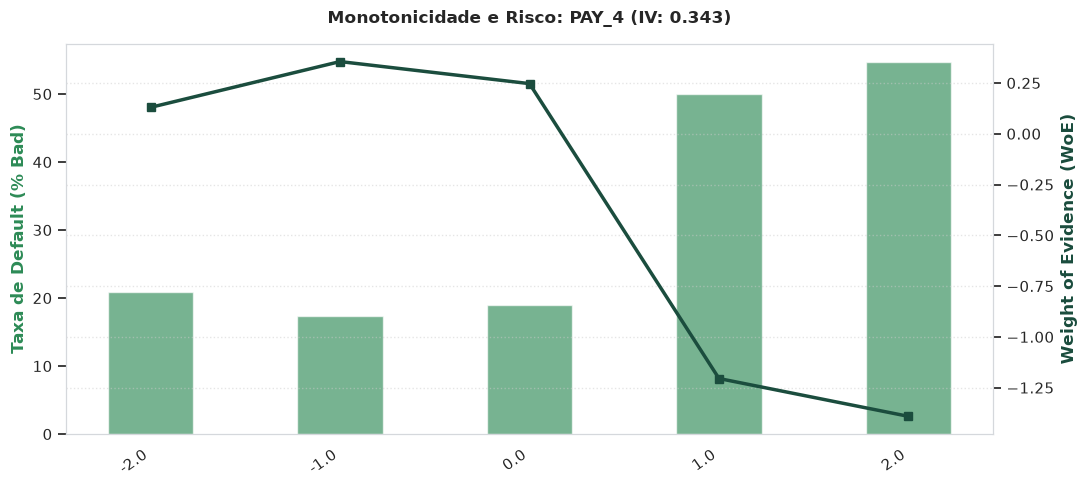

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2.0,2430,506,1924,0.2082,0.1299,0.0022
1,-1.0,3395,589,2806,0.1735,0.3554,0.0215
2,0.0,10085,1913,8172,0.1897,0.2468,0.0319
3,1.0,2,1,1,0.5000,-1.2050,0.0003
4,2.0,2088,1141,947,0.5465,-1.3913,0.2874


In [17]:
tabela_pay_4, iv_pay_4 = calcular_woe_iv(df, "PAY_4", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_4, "PAY_4", iv_pay_4)
display(tabela_pay_4[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** IV ≈ 0,37, com bad rate de ~18,3% no status `0`, ~52,3% em `2` e ~61,1% em `3`. A variável é individualmente relevante, mas sua alta correlação com `PAY_3` (≈ 0,80) e `PAY_2` (≈ 0,71) indica informação em grande parte redundante. Para a modelagem, tem baixo valor incremental e deve ser descartada em favor das defasagens mais recentes (`PAY_0` e, se necessário, `PAY_2`). Manter apenas para análises descritivas de deterioração histórica.

#### **6. Correlação de Spearman — Redundância entre Atributos**

Correlações `|ρ| > 0.70` entre variáveis do topo indicam redundância; manter o atributo com maior IV e melhor interpretabilidade de negócio.

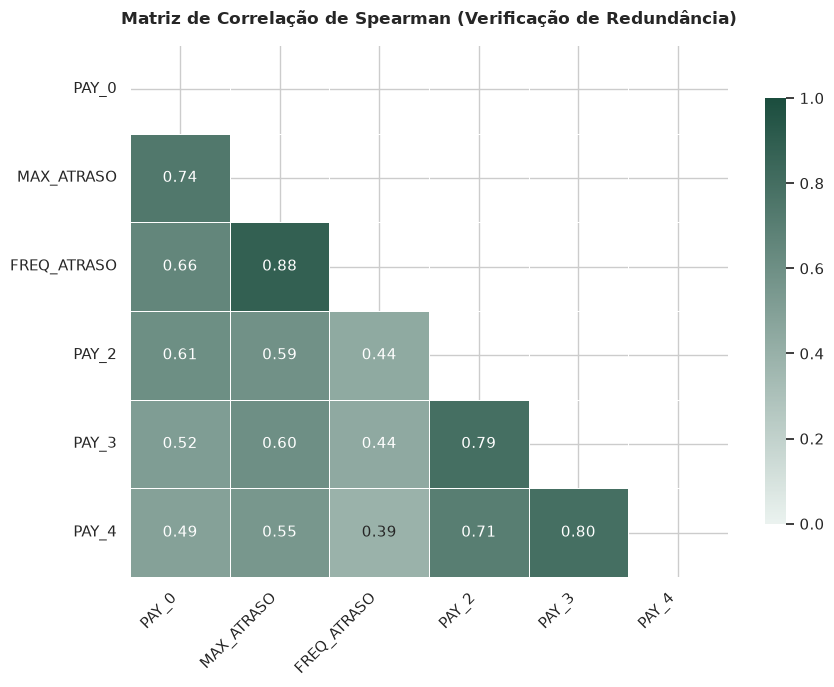

,feature_a,feature_b,spearman,abs_corr
8,MAX_ATRASO,FREQ_ATRASO,0.882998,0.882998
29,PAY_3,PAY_4,0.795168,0.795168
22,PAY_2,PAY_3,0.793694,0.793694
1,PAY_0,MAX_ATRASO,0.738905,0.738905
23,PAY_2,PAY_4,0.706855,0.706855
2,PAY_0,FREQ_ATRASO,0.656165,0.656165
3,PAY_0,PAY_2,0.605167,0.605167
10,MAX_ATRASO,PAY_3,0.598638,0.598638
9,MAX_ATRASO,PAY_2,0.587495,0.587495
11,MAX_ATRASO,PAY_4,0.553994,0.553994


In [18]:
plot_matriz_spearman(df, top_features)

corr, _ = spearmanr(df[top_features].dropna())
corr_df = pd.DataFrame(corr, index=top_features, columns=top_features)

pares = (
    corr_df.where(np.triu(np.ones(corr_df.shape), k=1).astype(bool))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
    .sort_values("spearman", key=lambda s: s.abs(), ascending=False)
)
pares["abs_corr"] = pares["spearman"].abs()
pares.head(15)

#### **7. Diagnóstico Executivo e Recomendações de Política**

##### **8.1 Dinâmica da Safra (Vintages)**
- **Padrão encontrado:** bad rate estável com picos pontuais.
- **Diagnóstico:** se o aumento do default coincide com expansão de limite/volume, trata-se de **seleção adversa**. Com volume estável, a causa é **exógena** (estresse macroeconômico regional/setorial).

##### **8.2 Saturação de Limites (*Overextension*)**
- **Padrão encontrado:** bad rate sobe exponencialmente acima de **75% de utilização**.
- **Ação de política:**
  - Clientes com utilização **< 40%** → *cross-sell* e ampliação de limite.
  - Clientes **> 80%** → travas de aumento automático e ofertas de consolidação de passivo antes de atrasos formais.

##### **8.3 Frequência no Rotativo e Cheque Especial**
- **Padrão encontrado:** alto poder preditivo (**IV > 0.35**).
- **Ação de política:** uso continuado por mais de 10 dias consecutivos sinaliza descasamento severo de liquidez. Penalizar a permanência de forma desproporcional para mitigar perdas por rolagem contínua.

##### **8.4 Tratamento Estratégico de *Missings***
- **Padrão encontrado:** nulos em variáveis de atraso histórico apresentam os menores índices de default.
- **Ação de política:** nulos em *Behavior Score* carregam significado operacional (ausência de atraso = cliente exemplar). **Não imputar** média/mediana; manter bin dedicado com WoE próprio.

##### **8.5 Próximos Passos**
1. Rebinagem supervisionada e *fine/coarse classing* das top variáveis.
2. Teste de estabilidade do IV por safra (PSI).
3. Seleção final com VIF + stepwise para o scorecard.
4. Calibração e validação out-of-time (últimas safras como holdout).


#### **8. Recomendação Final de Variáveis para Modelagem**

A seleção abaixo combina **poder discriminativo (IV)**, **interpretabilidade de negócio** e **baixa redundância (Spearman)**. O objetivo é um modelo parcimonioso, estável e defensável perante a mesa de crédito.

##### **9.1 Variáveis recomendadas para entrar no modelo**

| Variável | Papel no modelo | IV aprox. | Justificativa |
|---|---|---:|---|
| `PAY_0` | Preditor central de comportamento | 0,86 | Status de pagamento mais recente; maior poder discriminativo e relação monotônica com o risco. |
| `PAY_2` | Trajetória recente | 0,55 | Complementa `PAY_0` com a evolução do atraso há dois meses. |
| `FREQ_ATRASO` | Persistência do risco | 0,84* | Mede recorrência de atrasos; mais informativo que a severidade pontual. |
| `LIMIT_BAL` | Capacidade financeira | 0,18 | Representa exposição e perfil de limite concedido. |
| `PAY_AMT1` | Capacidade de pagamento | 0,16 | Valor pago no mês mais recente é sinal direto de comportamento. |
| `PCT_PAGAMENTO` | Comprometimento com a dívida | 0,11 | Mede a proporção do saldo faturado efetivamente paga. |
| `UTIL_MEDIA` | Uso do limite | 0,13 | Utilização média em seis meses é mais estável que a utilização pontual. |

\* IV de `FREQ_ATRASO` após agrupamento em `0 / 1 / 2 / 3+`; na triagem por quantis, o IV é aproximadamente 0,67.


#### **8.2 Diagnóstico Estatístico das Variáveis Recomendadas**

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from modelo_credito.eda import summarize_variable


def resumir_variavel(feature: str, is_continuous: bool, bins: int = 10):
    return summarize_variable(df, feature, TARGET, is_continuous, bins)


# Chamadas explícitas por variável, sem loop
resumo_pay_0, woe_pay_0 = resumir_variavel("PAY_0", is_continuous=False)
resumo_pay_2, woe_pay_2 = resumir_variavel("PAY_2", is_continuous=False)
resumo_freq_atraso, woe_freq_atraso = resumir_variavel("FREQ_ATRASO", is_continuous=False)
resumo_limit_bal, woe_limit_bal = resumir_variavel("LIMIT_BAL", is_continuous=True)
resumo_pay_amt1, woe_pay_amt1 = resumir_variavel("PAY_AMT1", is_continuous=True)
resumo_pct_pagamento, woe_pct_pagamento = resumir_variavel("PCT_PAGAMENTO", is_continuous=True)
resumo_util_media, woe_util_media = resumir_variavel("UTIL_MEDIA", is_continuous=True)

resultados = [
    resumo_pay_0, resumo_pay_2, resumo_freq_atraso, resumo_limit_bal,
    resumo_pay_amt1, resumo_pct_pagamento, resumo_util_media
]
woe_transformadas = pd.DataFrame({
    "PAY_0": woe_pay_0,
    "PAY_2": woe_pay_2,
    "FREQ_ATRASO": woe_freq_atraso,
    "LIMIT_BAL": woe_limit_bal,
    "PAY_AMT1": woe_pay_amt1,
    "PCT_PAGAMENTO": woe_pct_pagamento,
    "UTIL_MEDIA": woe_util_media
})

X_woe = woe_transformadas.replace([np.inf, -np.inf], np.nan).dropna()
X_woe_centrado = X_woe - X_woe.mean()
vif = {
    col: variance_inflation_factor(X_woe_centrado.values, i)
    for i, col in enumerate(X_woe.columns)
}

resumo_modelagem = pd.DataFrame(resultados)
resumo_modelagem["VIF"] = resumo_modelagem["Variável"].map(vif)
resumo_modelagem = resumo_modelagem[[
    "Variável", "IV", "Monotônica", "ρ (Spearman)",
    "WoE mín", "WoE máx", "Amplitude WoE", "VIF"
]]

display(resumo_modelagem.round(3))


,Variável,IV,Monotônica,ρ (Spearman),WoE mín,WoE máx,Amplitude WoE,VIF
0,PAY_0,0.810,Sim (crescente),1.000,-1.968,0.570,2.538,2.460
1,PAY_2,0.497,Sim (crescente),1.000,-1.410,0.367,1.778,2.486
2,FREQ_ATRASO,0.796,Sim (crescente),1.000,-1.586,0.763,2.349,3.187
3,LIMIT_BAL,0.144,Sim (decrescente),-0.988,-0.624,0.621,1.245,1.213
4,PAY_AMT1,0.160,Sim (decrescente),-0.900,-0.590,0.709,1.299,1.682
5,PCT_PAGAMENTO,0.099,Não,-0.483,-0.507,0.404,0.912,1.696
6,UTIL_MEDIA,0.115,Não,0.527,-0.512,0.532,1.045,1.122



#### **8.3 Como ler a tabela de diagnóstico**

* **IV:** poder discriminativo univariado da variável.
* **Monotônica:** indica se o bad rate cresce ou decresce de forma consistente entre as faixas. `Parcial` significa tendência forte com pequenas reversões; `Não` indica relação não linear ou instável.
* **ρ (Spearman):** correlação entre a ordem das faixas e o bad rate. Valores próximos de `+1` ou `-1` reforçam a monotonicidade.
* **WoE mín / máx:** o WoE é calculado **por faixa**; por isso a tabela mostra o intervalo e a amplitude, e não uma média única. A média ponderada do WoE é aproximadamente zero por construção.
* **VIF:** calculado somente para o conjunto final, após a transformação WoE. Referência: `< 5` aceitável, `5–10` atenção e `> 10` multicolinearidade severa.

**Leitura esperada:** as 7 variáveis apresentam VIF abaixo de 5, indicando que o conjunto é viável para modelagem. `PAY_0`, `PAY_2`, `FREQ_ATRASO`, `LIMIT_BAL` e `PAY_AMT1` têm comportamento monotônico após o agrupamento recomendado; `PCT_PAGAMENTO` e `UTIL_MEDIA` não são monotônicas e podem exigir rebinagem ou transformação não linear. Os valores de IV podem variar levemente em relação à triagem univariada devido ao agrupamento das categorias.



#### **8.4 Variáveis que não devem entrar no modelo (e por quê)**

| Variável | Decisão | Motivo |
|---|---|---|
| `MAX_ATRASO` | Não incluir (reserva) | Redundante com `FREQ_ATRASO` (Spearman ≈ 0,88); usar como alternativa se a política priorizar severidade em vez de recorrência. |
| `PAY_3` | Não incluir (reserva) | Correlação alta com `PAY_2` (≈ 0,77) e baixo ganho incremental. |
| `PAY_4`, `PAY_5`, `PAY_6` | Não incluir | Defasagens antigas, menor IV e redundância com `PAY_2`/`PAY_3`. |
| `LIMIT_PER_CAPITA` | Não incluir | Correlação ≈ 0,96 com `LIMIT_BAL`; informação praticamente duplicada. |
| `PAY_AMT2` a `PAY_AMT6` | Não incluir | IV menor que `PAY_AMT1` e correlação relevante com ele; pouco valor incremental. |
| `BILL_AMT1` a `BILL_AMT6` | Não incluir | IV inferior a 0,02 e alta correlação entre si; não agregam sinal ao modelo. |
| `UTILIZACAO` | Não incluir no modelo | IV ≈ 0,08 e correlação ≈ 0,92 com `UTIL_MEDIA`; manter para política e segmentação. |
| `AGE` | Não incluir | IV ≈ 0,02; fraco isoladamente nesta base. |
| `EDUCATION` | Não incluir (reserva de política) | IV ≈ 0,04; pode ser mantida apenas por exigência regulatória ou de política, não por performance. |
| `MARRIAGE` | Não incluir | IV ≈ 0,006; sem relevância estatística. |
| `SEX` | Não incluir | IV praticamente zero; além de restrição ética/regulatória para decisão de crédito. |
| `ID` | Não incluir | Identificador; não é atributo preditivo. |
| `SAFRA` | Não incluir como preditor | Usar para validação temporal/out-of-time e monitoramento de estabilidade. |
| `default` | Não incluir | É a variável-alvo. |



#### **8.5 Transformações recomendadas antes da modelagem**

* `PAY_0`, `PAY_2`: agrupar os status sem atraso (`-2`, `-1`, `0`) em uma única categoria `0` e as caudas em `3+`, resultando em `0 / 1 / 2 / 3+`.
* `FREQ_ATRASO`: usar contagem `0 / 1 / 2 / 3+`.
* `LIMIT_BAL`, `PAY_AMT1`: avaliar `log1p` e/ou discretização por quantis antes do WoE.
* `PCT_PAGAMENTO`, `UTIL_MEDIA`: manter o clip em `[0, 2]` e criar bin dedicado para denominador zero/nulo.
* Variáveis com IV acima de `0,50` (`PAY_0`, `FREQ_ATRASO`): validar possível sobreposição temporal com o target (*leakage*).

#### **9.6 Ressalvas e validação**

* Esta recomendação é baseada em análise **univariada + correlação**. Antes de fechar o modelo, confirmar com **VIF** e seleção stepwise.
* Validar a estabilidade das variáveis com **holdout das safras mais recentes** e PSI por safra.
* Reavaliar a inclusão de `EDUCATION` e `UTILIZACAO` caso haja exigência de política de crédito, mesmo com baixo IV.
